 ### Linear Algebra in UPI QR Code Analysis

 **Install required libraries**

In [1]:
%pip install numpy pandas pillow qrcode[pil] opencv-python matplotlib

  Using cached qrcode-8.2-py3-none-any.whl.metadata (17 kB)
Using cached qrcode-8.2-py3-none-any.whl (45 kB)
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


 **Import libraries**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter, ImageDraw
import qrcode
import cv2
from pathlib import Path

OUTPUT_DIR = Path("upi_qr_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("Output folder:", OUTPUT_DIR.resolve())

NumPy: 1.26.4
OpenCV: 4.8.1
Output folder: C:\Users\moham\upi_qr_outputs


 **Generate a dummy UPI-style QR code**

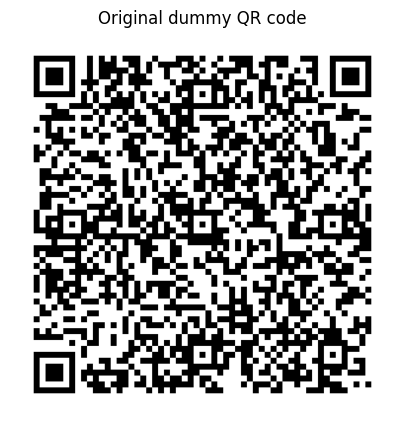

Image dimensions (width, height): (650, 650)
Dummy payload: upi://pay?pa=demo.merchant%40example.com&pn=Demo%20Merchant&am=10.00&cu=INR&tn=LINEAR%20ALGEBRA%20CASE%20STUDY


In [3]:
dummy_payload = (
    "upi://pay?pa=demo.merchant%40example.com"
    "&pn=Demo%20Merchant&am=10.00&cu=INR"
    "&tn=LINEAR%20ALGEBRA%20CASE%20STUDY"
)

qr = qrcode.QRCode(
    version=None,
    error_correction=qrcode.constants.ERROR_CORRECT_H,
    box_size=10,
    border=4
)
qr.add_data(dummy_payload)
qr.make(fit=True)

original = qr.make_image(fill_color="black", back_color="white").convert("L")
original.save(OUTPUT_DIR / "sample_dummy_upi_qr.png")

plt.figure(figsize=(5, 5))
plt.imshow(original, cmap="gray")
plt.title("Original dummy QR code")
plt.axis("off")
plt.show()

print("Image dimensions (width, height):", original.size)
print("Dummy payload:", dummy_payload)

 **Convert the image into a matrix**

Matrix shape (rows, columns): (650, 650)
Top-left 10 x 10 matrix block:
[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]


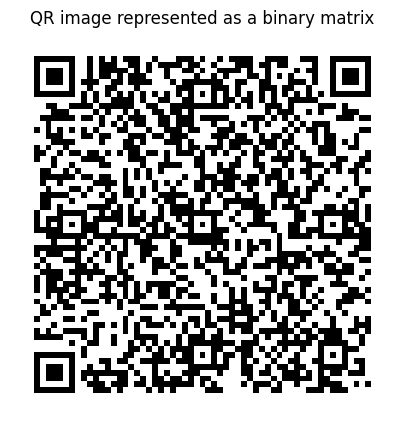

In [4]:
def to_binary_matrix(image):
    """Convert grayscale image pixels to a matrix: black=1, white=0."""
    gray = np.asarray(image.convert("L"))
    return (gray < 128).astype(np.uint8)

A = to_binary_matrix(original)

print("Matrix shape (rows, columns):", A.shape)
print("Top-left 10 x 10 matrix block:")
print(A[:10, :10])

plt.figure(figsize=(5, 5))
plt.imshow(A, cmap="gray_r", interpolation="nearest")
plt.title("QR image represented as a binary matrix")
plt.axis("off")
plt.show()

 **Create controlled image transformations**

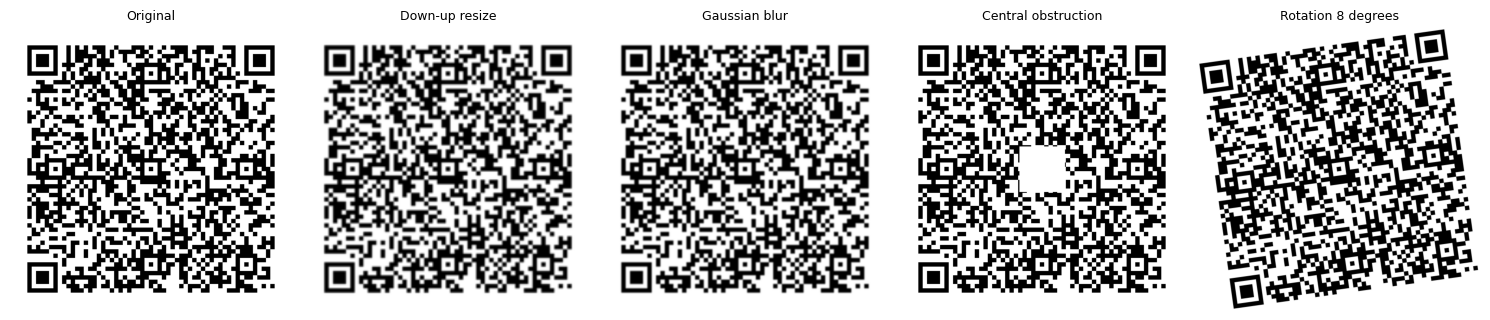

In [5]:
# A. Reduce the resolution and enlarge it again
small = original.resize(
    (max(50, original.width // 3), max(50, original.height // 3)),
    Image.Resampling.BILINEAR
)
down_up = small.resize(original.size, Image.Resampling.BILINEAR)

# B. Apply Gaussian blur
blurred = original.filter(ImageFilter.GaussianBlur(radius=1.5))

# C. Cover a central square to simulate partial obstruction
obstructed = original.copy()
draw = ImageDraw.Draw(obstructed)
w, h = obstructed.size
draw.rectangle(
    (int(w * 0.42), int(h * 0.42), int(w * 0.58), int(h * 0.58)),
    fill=255
)

# D. Rotate the image slightly
rotated = original.rotate(
    8, resample=Image.Resampling.BICUBIC, expand=False, fillcolor=255
)

variants = {
    "Original": original.copy(),
    "Down-up resize": down_up,
    "Gaussian blur": blurred,
    "Central obstruction": obstructed,
    "Rotation 8 degrees": rotated
}

fig, axes = plt.subplots(1, len(variants), figsize=(15, 3.5))
for ax, (name, image) in zip(axes, variants.items()):
    ax.imshow(image, cmap="gray")
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

 **Matrix difference measures**

In [6]:
def compare_matrices(original_matrix, transformed_matrix):
    """Compare same-sized binary matrices using mismatch fraction and Frobenius norm."""
    if original_matrix.shape != transformed_matrix.shape:
        raise ValueError("Matrices must have the same shape before comparison.")
    difference = original_matrix.astype(float) - transformed_matrix.astype(float)
    mismatch_fraction = np.mean(original_matrix != transformed_matrix)
    frobenius_norm = np.linalg.norm(difference, ord="fro")
    return mismatch_fraction, frobenius_norm, difference

# Resize each image to original dimensions before comparing pixel positions.
# This is a simple alignment step for the experiment; it can itself affect pixels.

 **Test QR decoding**

In [7]:
detector = cv2.QRCodeDetector()

def decode_qr(image):
    """Return decoded text, or an empty string if decoding fails."""
    rgb = np.asarray(image.convert("RGB"))
    decoded_text, points, straight_qrcode = detector.detectAndDecode(rgb)
    return decoded_text

results = []
difference_matrices = {}

for name, image in variants.items():
    aligned_image = image if image.size == original.size else image.resize(original.size)
    B = to_binary_matrix(aligned_image)
    mismatch, frobenius, D = compare_matrices(A, B)
    decoded_text = decode_qr(image)
    decoded = bool(decoded_text)
    payload_matches = decoded and (decoded_text == dummy_payload)

    results.append({
        "Variant": name,
        "Pixel mismatch fraction": mismatch,
        "Pixel mismatch percent": mismatch * 100,
        "Frobenius norm": frobenius,
        "Decoded successfully": decoded,
        "Payload matched exactly": payload_matches
    })
    difference_matrices[name] = D

results_df = pd.DataFrame(results)
results_df

,Variant,Pixel mismatch fraction,Pixel mismatch percent,Frobenius norm,Decoded successfully,Payload matched exactly
0,Original,0.000000,0.000000,0.000000,True,True
1,Down-up resize,0.008507,0.850651,59.949979,True,True
2,Gaussian blur,0.003830,0.382959,40.224371,True,True
3,Central obstruction,0.013740,1.373964,76.190551,True,True
4,Rotation 8 degrees,0.402535,40.253491,412.396654,True,True


 **Visualize the matrix difference**

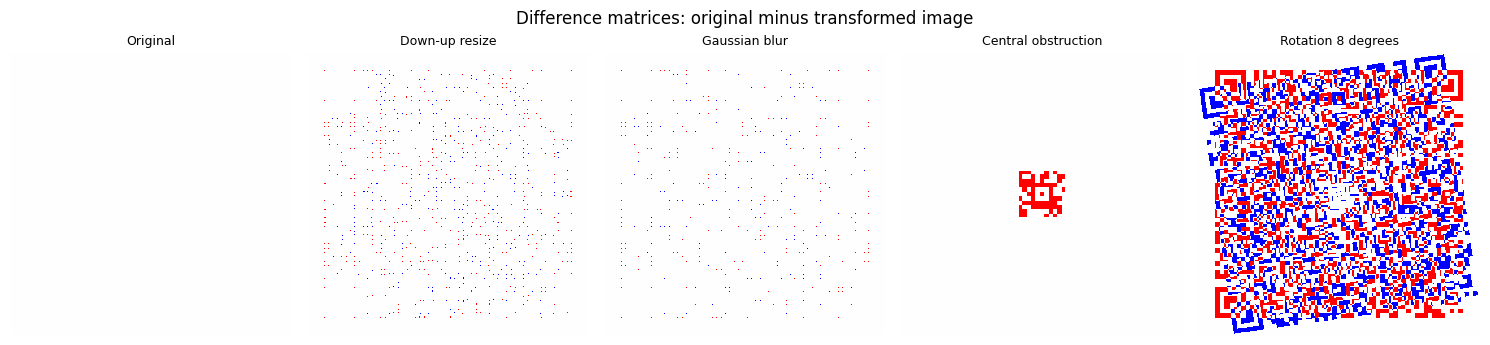

In [8]:
fig, axes = plt.subplots(1, len(variants), figsize=(15, 3.5))
for ax, (name, image) in zip(axes, variants.items()):
    aligned_image = image if image.size == original.size else image.resize(original.size)
    B = to_binary_matrix(aligned_image)
    D = A.astype(int) - B.astype(int)
    ax.imshow(D, cmap="bwr", vmin=-1, vmax=1, interpolation="nearest")
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.suptitle("Difference matrices: original minus transformed image")
plt.tight_layout()
plt.show()

 **Plot pixel mismatch**

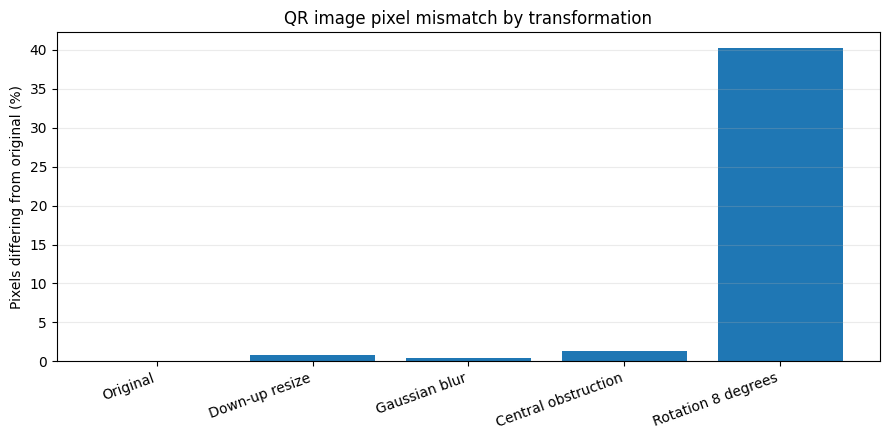

In [9]:
plt.figure(figsize=(9, 4.5))
plt.bar(results_df["Variant"], results_df["Pixel mismatch percent"])
plt.ylabel("Pixels differing from original (%)")
plt.title("QR image pixel mismatch by transformation")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

 **Save results**

In [10]:
csv_path = OUTPUT_DIR / "upi_qr_experiment_results.csv"
results_df.to_csv(csv_path, index=False)

print("Results saved to:", csv_path.resolve())
print("QR image saved to:", (OUTPUT_DIR / "sample_dummy_upi_qr.png").resolve())
results_df

Results saved to: C:\Users\moham\upi_qr_outputs\upi_qr_experiment_results.csv
QR image saved to: C:\Users\moham\upi_qr_outputs\sample_dummy_upi_qr.png


,Variant,Pixel mismatch fraction,Pixel mismatch percent,Frobenius norm,Decoded successfully,Payload matched exactly
0,Original,0.000000,0.000000,0.000000,True,True
1,Down-up resize,0.008507,0.850651,59.949979,True,True
2,Gaussian blur,0.003830,0.382959,40.224371,True,True
3,Central obstruction,0.013740,1.373964,76.190551,True,True
4,Rotation 8 degrees,0.402535,40.253491,412.396654,True,True
